In [ ]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scn.data import drop_duplicate_share_classes, get_constituents, download_prices, clean_prices, log_returns
from scn.network import eigen_decomposition, mp_upper_bound, remove_market_mode
from scn.plots import sector_heatmap

cons = get_constituents()
prices = download_prices(cons["ticker"].tolist(), "2015-01-01", "2025-12-31")
returns = log_returns(drop_duplicate_share_classes(clean_prices(prices)))
sectors = cons.set_index("ticker")["sector"].loc[returns.columns]
C = returns.corr()
T, N = returns.shape
print(N, "stocks,", T, "days")

457 stocks, 2764 days


In [2]:
vals, vecs = eigen_decomposition(C)
print("sum of eigenvalues:", round(vals.sum(), 1), "(always equals N)")
print("largest 10:", vals[:10].round(1))

noise_var = 1 - vals[0] / N
lam_max = mp_upper_bound(N, T, noise_var)
print(f"noise bound: {lam_max:.2f}")
print("eigenvalues above the bound:", (vals > lam_max).sum())
print(f"market mode explains {vals[0] / N:.1%} of all variance")

sum of eigenvalues: 457.0 (always equals N)
largest 10: [165.9  24.6  17.3   8.6   6.4   6.3   5.2   4.6   4.    3.8]
noise bound: 1.26
eigenvalues above the bound: 35
market mode explains 36.3% of all variance


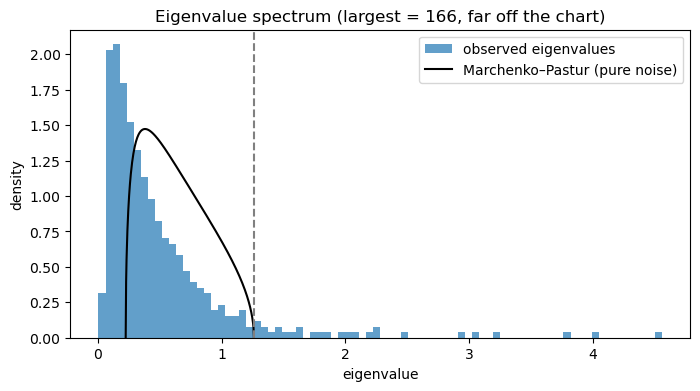

In [3]:
q = N / T
lam_min = noise_var * (1 - np.sqrt(q)) ** 2
x = np.linspace(lam_min, lam_max, 300)
mp = np.sqrt((lam_max - x) * (x - lam_min)) / (2 * np.pi * q * noise_var * x)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(vals[vals < 5], bins=80, density=True, alpha=0.7, label="observed eigenvalues")
ax.plot(x, mp, "k", lw=1.5, label="Marchenko–Pastur (pure noise)")
ax.axvline(lam_max, ls="--", c="grey")
ax.set_xlabel("eigenvalue")
ax.set_ylabel("density")
ax.set_title(f"Eigenvalue spectrum (largest = {vals[0]:.0f}, far off the chart)")
ax.legend()
plt.show()

In [4]:
market = pd.Series(vecs[:, 0], index=C.index)
market *= np.sign(market.sum())          # an eigenvector's sign is arbitrary, so make it positive

print("share of stocks with a positive weight:", (market > 0).mean())
mode_returns = returns @ market
print("correlation with an equal-weighted index:",
      round(np.corrcoef(mode_returns, returns.mean(axis=1))[0, 1], 3))

share of stocks with a positive weight: 1.0
correlation with an equal-weighted index: 0.999


In [5]:
for k in range(1, 8):
    v = pd.Series(vecs[:, k], index=C.index)
    top = v.abs().sort_values(ascending=False).head(15).index
    print(f"eigenvector {k + 1} (λ = {vals[k]:.1f}):", sectors.loc[top].value_counts().head(3).to_dict())

eigenvector 2 (λ = 24.6): {'Utilities': 15}
eigenvector 3 (λ = 17.3): {'Information Technology': 9, 'Health Care': 3, 'Energy': 2}
eigenvector 4 (λ = 8.6): {'Real Estate': 11, 'Health Care': 4}
eigenvector 5 (λ = 6.4): {'Energy': 15}
eigenvector 6 (λ = 6.3): {'Financials': 6, 'Industrials': 3, 'Health Care': 2}
eigenvector 7 (λ = 5.2): {'Consumer Discretionary': 7, 'Financials': 4, 'Health Care': 2}
eigenvector 8 (λ = 4.6): {'Health Care': 13, 'Consumer Discretionary': 2}


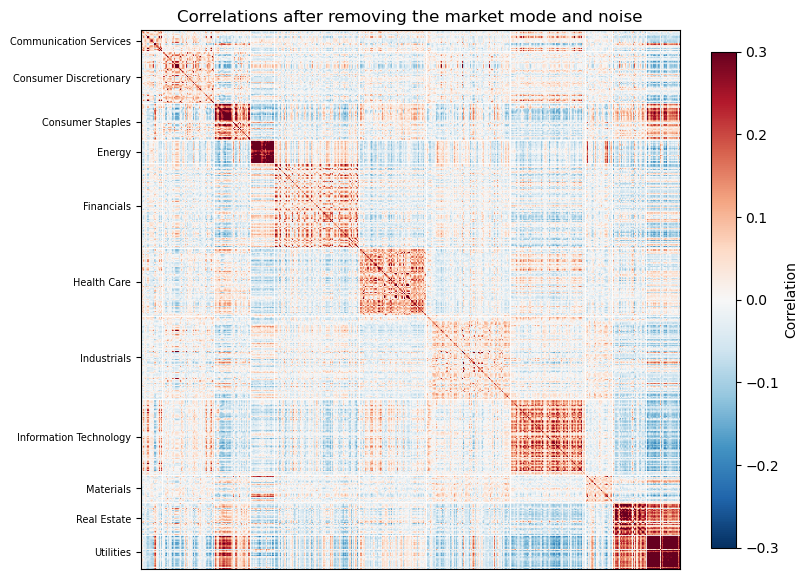

filtered, same sector:      0.087
filtered, different sector: -0.011


In [6]:
Cg = remove_market_mode(C, T)
sector_heatmap(Cg, sectors, "Correlations after removing the market mode and noise", vmax=0.3)
plt.show()

n = len(Cg)
off = ~np.eye(n, dtype=bool)
same = sectors.values[:, None] == sectors.values[None, :]
print(f"filtered, same sector:      {Cg.values[same & off].mean():.3f}")
print(f"filtered, different sector: {Cg.values[~same].mean():.3f}")

In [7]:
smallest = pd.Series(vecs[:, -1], index=C.index)
print("smallest eigenvalue:", round(vals[-1], 4))
smallest.abs().sort_values(ascending=False).head(4)

smallest eigenvalue: 0.0043


GOOGL    0.706025
GOOG     0.705657
CMS      0.015496
MA       0.008858
dtype: float64

In [8]:
for k in [1, 2]:
    v = pd.Series(vecs[:, k], index=C.index)
    print(f"eigenvector {k + 1}  +end:", sectors.loc[v.nlargest(15).index].value_counts().head(3).to_dict())
    print(f"eigenvector {k + 1}  -end:", sectors.loc[v.nsmallest(15).index].value_counts().head(3).to_dict())

eigenvector 2  +end: {'Utilities': 15}
eigenvector 2  -end: {'Information Technology': 12, 'Energy': 2, 'Industrials': 1}
eigenvector 3  +end: {'Information Technology': 11, 'Health Care': 3, 'Consumer Discretionary': 1}
eigenvector 3  -end: {'Energy': 9, 'Financials': 6}


In [9]:
upper = np.triu(np.ones(C.shape, dtype=bool), k=1)     # each pair once
pairs = C.where(upper).stack()
pairs[pairs > 0.9].sort_values(ascending=False)

GOOG  GOOGL    0.994666
NWS   NWSA     0.971662
UDR   VMRK     0.915751
FRT   REG      0.914190
FITB  RF       0.908517
MET   PRU      0.905479
dtype: float64